In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

main = pd.read_stata("../data/raw/coding_suseti_pmt.dta", convert_categoricals=False)
labels = pd.read_stata("../data/raw/mistargeting_CORRECTED.dta", convert_categoricals=False)
df = main.merge(labels[["hhid_suseti", "poor"]], left_on="hhid", right_on="hhid_suseti")

os.makedirs("../outputs/figures", exist_ok=True)
print("Shape:", df.shape)

Matplotlib is building the font cache; this may take a moment.


Shape: (5756, 349)


In [2]:
print(f"Share poor (all): {df['poor'].mean():.1%}")
print(f"Number of villages: {df['hhea'].nunique()}")

display(df.groupby("prop")["poor"].agg(["mean", "count"]))
display(df.groupby("urban")["poor"].agg(["mean", "count"]))

Share poor (all): 35.3%
Number of villages: 640


,mean,count
prop,,
12,0.325086,1455
33,0.409073,2601
73,0.289334,1697


,mean,count
urban,,
0,0.397545,2933
1,0.305674,2820


Central Java is the largest province (33) and it has the most poverty.
Rural villages (40%) are poorer than urban ones (31%).
The count is not adding up to 5756 but to 5753, because 3 households are missing, as they are the 3 households without consumption.

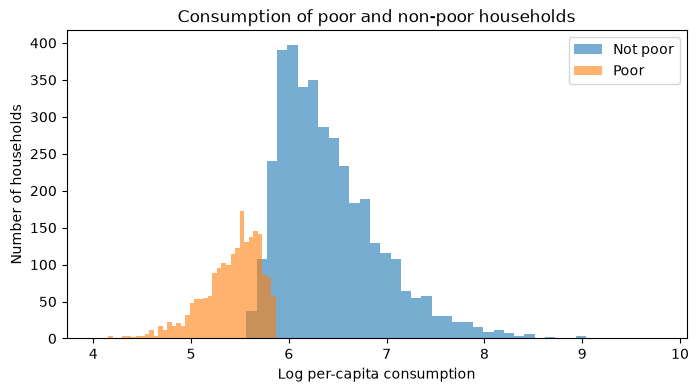

In [3]:
# Distribution of consumption, histogram of log consumption by poor vs non-poor

plt.figure(figsize=(8, 4))
plt.hist(df.loc[df["poor"] == 0, "LOGCONSUMPTION"], bins=40, alpha=0.6, label="Not poor")
plt.hist(df.loc[df["poor"] == 1, "LOGCONSUMPTION"], bins=40, alpha=0.6, label="Poor")
plt.xlabel("Log per-capita consumption")
plt.ylabel("Number of households")
plt.title("Consumption of poor and non-poor households")
plt.legend()
plt.savefig("../outputs/figures/eda_consumption.png", dpi=200, bbox_inches="tight")
plt.show()

There is a small overlap zone, which we can see by the overlap of the two colors. It comes from the poverty line because the same level of consumption can leed in one region to being poor and in another region to be not poor. 

In [4]:
# Villages quotas

villages = df.groupby("hhea").agg(share=("share", "first"), n_poor=("poor", "sum"))
villages["n_slots"] = (8 * villages["share"]).round()

print("Number of slots per village:")
print(villages["n_slots"].value_counts().sort_index())
print(f"Villages with more poor households than slots: {(villages['n_poor'] > villages['n_slots']).mean():.1%}")

Number of slots per village:
n_slots
0.0     19
1.0    149
2.0    184
3.0    130
4.0     90
5.0     45
6.0     19
7.0      4
Name: count, dtype: int64
Villages with more poor households than slots: 54.1%


In [5]:
# What varies within a village

features = ["hhsize", "depratio", "tfloor", "twall", "troof", "toilet", "water", "lighting", "fcook", "house", "urban", "prop"]
features = [f for f in features if f in df.columns]   

rows = []
for f in features:
    total_var = df[f].var()
    within = df[f] - df.groupby("hhea")[f].transform("mean")
    rows.append({"feature": f, "share_within": within.var() / total_var})

variation = pd.DataFrame(rows).sort_values("share_within")
display(variation)

,feature,share_within
10,urban,0.000000
11,prop,0.000000
4,troof,0.165540
6,water,0.512064
8,fcook,0.514870
3,twall,0.611333
2,tfloor,0.623927
9,house,0.670062
5,toilet,0.682727
7,lighting,0.735877
